# Strip waveguide - width sweep

This notebook contains code that conduct mode analysis of strip waveguide using **Lumerical Mode** solver and **lumapi** interface. \
It does width sweep of the waveguide core and tracks moodes effective indices. \
The objective is to find the maximum waveguide width that supports single-mode operation.

In [135]:
%%capture

# Install dependencies specified in pyproject.toml
!uv pip install --reinstall --refresh -r pyproject.toml

%matplotlib widget

# Import modules
from datetime import datetime
import lumapi as lma
import matplotlib.pyplot as plt
import numpy as np
import photonix as px

In [136]:
%%html

<!-- Align table to the left -->
<style>
  table {margin-left: 0 !important;}
</style>

In [137]:
# Constants

um = 1e-6
nm = 1e-9
C = 299792458

# Simulation input

| Parameter                 | Description                                                                                   | Example                |
| :------------------------ | :-------------------------------------------------------------------------------------------- | :--------------------- |
| **wavelength_center**     | Wavelength for which simulation will be done. (i)                                             | `1.55*um`              |
| **core_thickness**        | Thickness of the burried oxide strip waveguide core.                                          | `220*nm`               |
| **core material**         | Material of strip waveguide core as defined in materials library of specified solver backend. | `Si (Silicon) - Palik` |
| **clad material**         | Material of strip waveguide clad as defined in materials library of specified solver backend. | `SiO2 (Glass) - Palik` |

In [138]:
# Si/SiO2/Si ????x220nm 1550nm
experiment_name = "si_h220nm_wsweep"

width_sweep = np.arange(50*nm, 2000*nm, 10*nm)

wavelength_center = 1.55*um
core_thickness = 220*nm

bottom_clad_thickness = 3*um
top_clad_thickness = 2*um

# https://optics.ansys.com/hc/en-us/articles/360034394614-Material-Database-in-FDTD-and-MODE
core_material = "Si (Silicon) - Palik"
clad_material = "SiO2 (Glass) - Palik"
substrate_material = "Si (Silicon) - Palik"

In [139]:
# Si3N4/SiO2/Si ????x360nm 1550nm
experiment_name = "si3n4_h360nm_wsweep"

width_sweep = np.arange(50*nm, 2000*nm, 10*nm)

wavelength_center = 1.55*um
core_thickness = 360*nm

bottom_clad_thickness = 5*um
top_clad_thickness = 5*um

# https://optics.ansys.com/hc/en-us/articles/360034394614-Material-Database-in-FDTD-and-MODE
core_material = "Si3N4 (Silicon Nitride) - Luke"
clad_material = "SiO2 (Glass) - Palik"
substrate_material = "Si (Silicon) - Palik"

In [140]:
field_intensity_log_decay = -6
initial_core_width = max(width_sweep)
initial_fde_width = 3 * initial_core_width
initial_fde_height = 12 * core_thickness

In [141]:
# Get solver
mode_solver = lma.MODE(hide=False)

In [142]:
# Materials fitting
mode_solver.switchtolayout()

def fit_material(material_name):
    wavelength_min = wavelength_center - 150*nm
    wavelength_max = wavelength_center + 150*nm

    try:
        mode_solver.deletematerial(f"{material_name} Fitted")
    except:
        pass

    material_fitted = mode_solver.copymaterial(material_name)
    mode_solver.setmaterial(material_fitted, "tolerance", 0.001)
    mode_solver.setmaterial(material_fitted, "max coefficients", 6)
    mode_solver.setmaterial(material_fitted, "specify fit range", True)
    mode_solver.setmaterial(material_fitted, "wavelength min", wavelength_min)
    mode_solver.setmaterial(material_fitted, "wavelength max", wavelength_max)
    mode_solver.setmaterial(material_fitted, "name", f"{material_name} Fitted")
    
    return f"{material_name} Fitted"

core_material = fit_material(core_material)
clad_material = fit_material(clad_material)
substrate_material = fit_material(substrate_material)

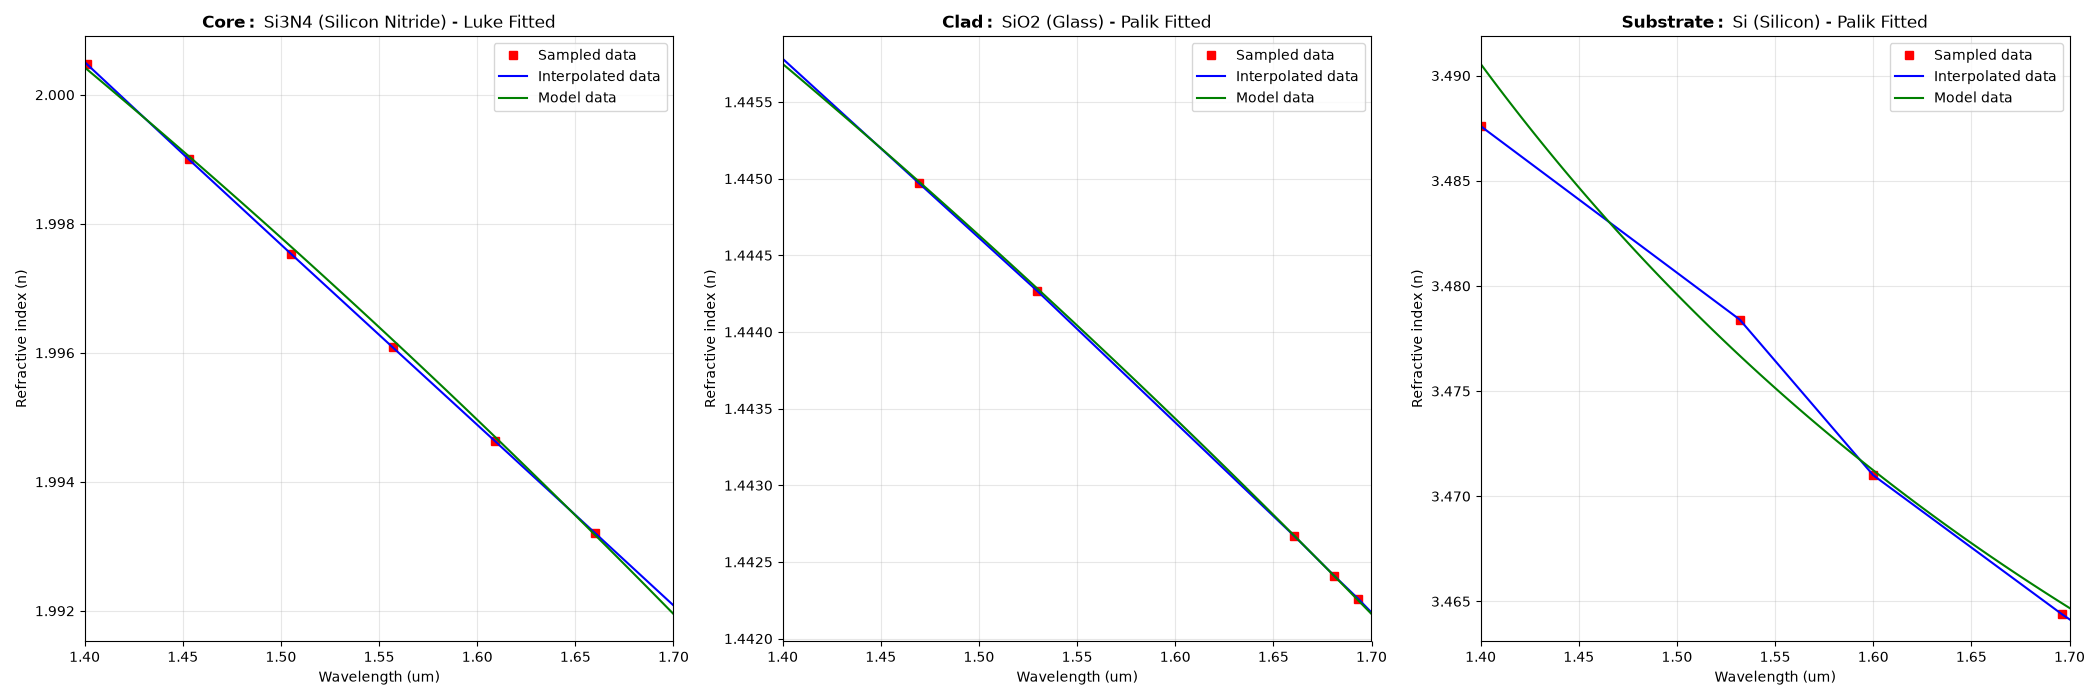

In [143]:
def plot_material(material, ax):
    ax.set_title(material)

    wvl_min = mode_solver.getmaterial(material, "wavelength min")
    wvl_max = mode_solver.getmaterial(material, "wavelength max")

    mat_permitivity_samples = mode_solver.getmaterial(material, "sampled data")

    f1 = mat_permitivity_samples[:, 0]
    mat_n_interpolated = mode_solver.getindex(material, f1).squeeze()
    mat_n_interpolated = np.column_stack((f1, mat_n_interpolated))

    f2 = C / np.linspace(wvl_min, wvl_max, 100)
    fmin = np.min(f2)
    fmax = np.max(f2)
    mat_n_model = mode_solver.getmodeindex(material, f2, 1, 1, 0, fmin, fmax);
    mat_n_model = np.column_stack((f2, mat_n_model))

    px.plot_material_n(
        mat_permitivity_samples,
        mat_n_interpolated,
        mat_n_model=mat_n_model,
        wavelength_min=wvl_min, wavelength_max=wvl_max,
        ax=ax
    )

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(21, 7))

# Core
plot_material(core_material, ax1)
ax1.set_title(f"$\\bf{{Core:}}$ {core_material}")

# Clad
plot_material(clad_material, ax2)
ax2.set_title(f"$\\bf{{Clad:}}$ {clad_material}")

# Substrate
plot_material(substrate_material, ax3)
ax3.set_title(f"$\\bf{{Substrate:}}$ {substrate_material}")

fig.tight_layout()
plt.show()

In [144]:
# Structure geometry

clad_thickness = bottom_clad_thickness + core_thickness + top_clad_thickness
clad_center_z = (top_clad_thickness - bottom_clad_thickness) / 2
substrate_thickness = 100*um
substrate_z_max = clad_center_z - clad_thickness/2
substrate_z_min = substrate_z_max - substrate_thickness

# Substrate
mode_solver.addrect(
    name="substrate",
    x=0, y=0, z_max=substrate_z_max, z_min=substrate_z_min,
    x_span=100*um, y_span=1*um,
    material=substrate_material,
)

# Clad
mode_solver.addrect(
    name="clad",
    x=0, y=0, z=clad_center_z,
    x_span=100*um, y_span=1*um, z_span=clad_thickness,
    material=clad_material,
)

# Core
mode_solver.addrect(
    name="core",
    x=0, y=0, z=0,
    x_span=initial_core_width, y_span=1*um, z_span=core_thickness,
    material=core_material,
)

In [145]:
# Simulation setup

mode_solver.addfde(
    solver_type="2D Y Normal",
    x=0, x_span = initial_fde_width,
    y=0,
    z=0, z_span = initial_fde_height,
    number_of_trial_modes=4,
    wavelength=wavelength_center,
)

# Mesh override
mode_solver.addmesh(
    set_maximum_mesh_step=True,
    override_x_mesh=True, dx=10*nm,
    override_y_mesh=True, dy=10*nm,
    override_z_mesh=True, dz=10*nm,
    based_on_a_structure=True,
    structure="core",
)

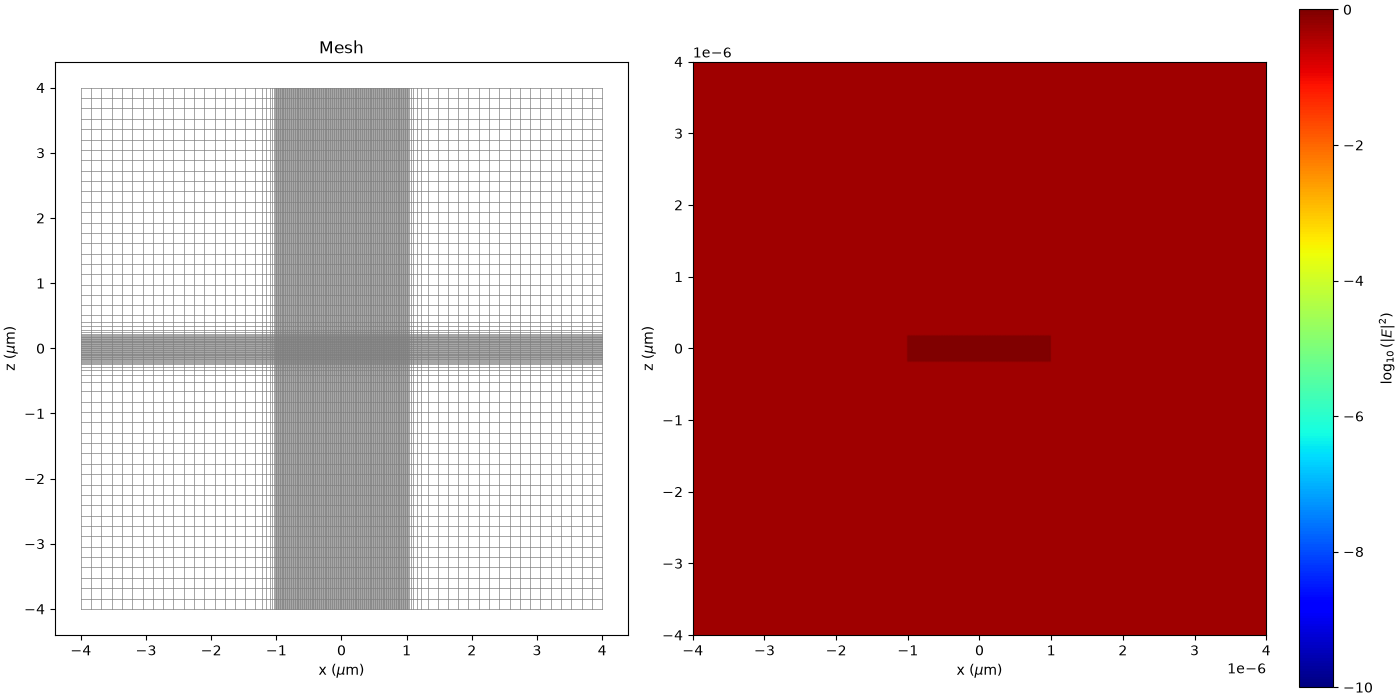

Current core width: 2000.0 nm
Current core height: 360.0 nm
Current fde width: 8.00 um
Current fde height: 8.00 um


In [146]:
# Simulation preview

mode_solver.mesh()
index = mode_solver.getresult("FDE::data::material", "index")
index_x, index_y, index_z = [np.squeeze(index[f"index_{a}"]) for a in ["x", "y", "z"]]
x, z = np.squeeze(index["x"]), np.squeeze(index["z"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)

# Grid
X, Z = np.meshgrid(x, z, indexing='ij')
ax1.plot(X * 1e6, Z * 1e6, color='gray', linestyle='-', linewidth=0.5)
ax1.plot(X.T * 1e6, Z.T * 1e6, color='gray', linestyle='-', linewidth=0.5)
ax1.set_title('Mesh')
ax1.set_xlabel(r'x ($\mu$m)')
ax1.set_ylabel(r'z ($\mu$m)')
ax1.set_aspect('equal')

px.plot_field(
    index_x, index_y, index_z, 
    x=x, z=z,
    vmin=-10, vmax=0,
    ax=ax2
)
plt.show()

current_core_width = mode_solver.getnamed("core", "x span")
current_core_height = mode_solver.getnamed("core", "z span")
current_fde_width = mode_solver.getnamed("FDE", "x span")
current_fde_height = mode_solver.getnamed("FDE", "z span")

print(f"Current core width: {current_core_width*1e9:.1f} nm")
print(f"Current core height: {current_core_height*1e9:.1f} nm")
print(f"Current fde width: {current_fde_width*1e6:.2f} um")
print(f"Current fde height: {current_fde_height*1e6:.2f} um")

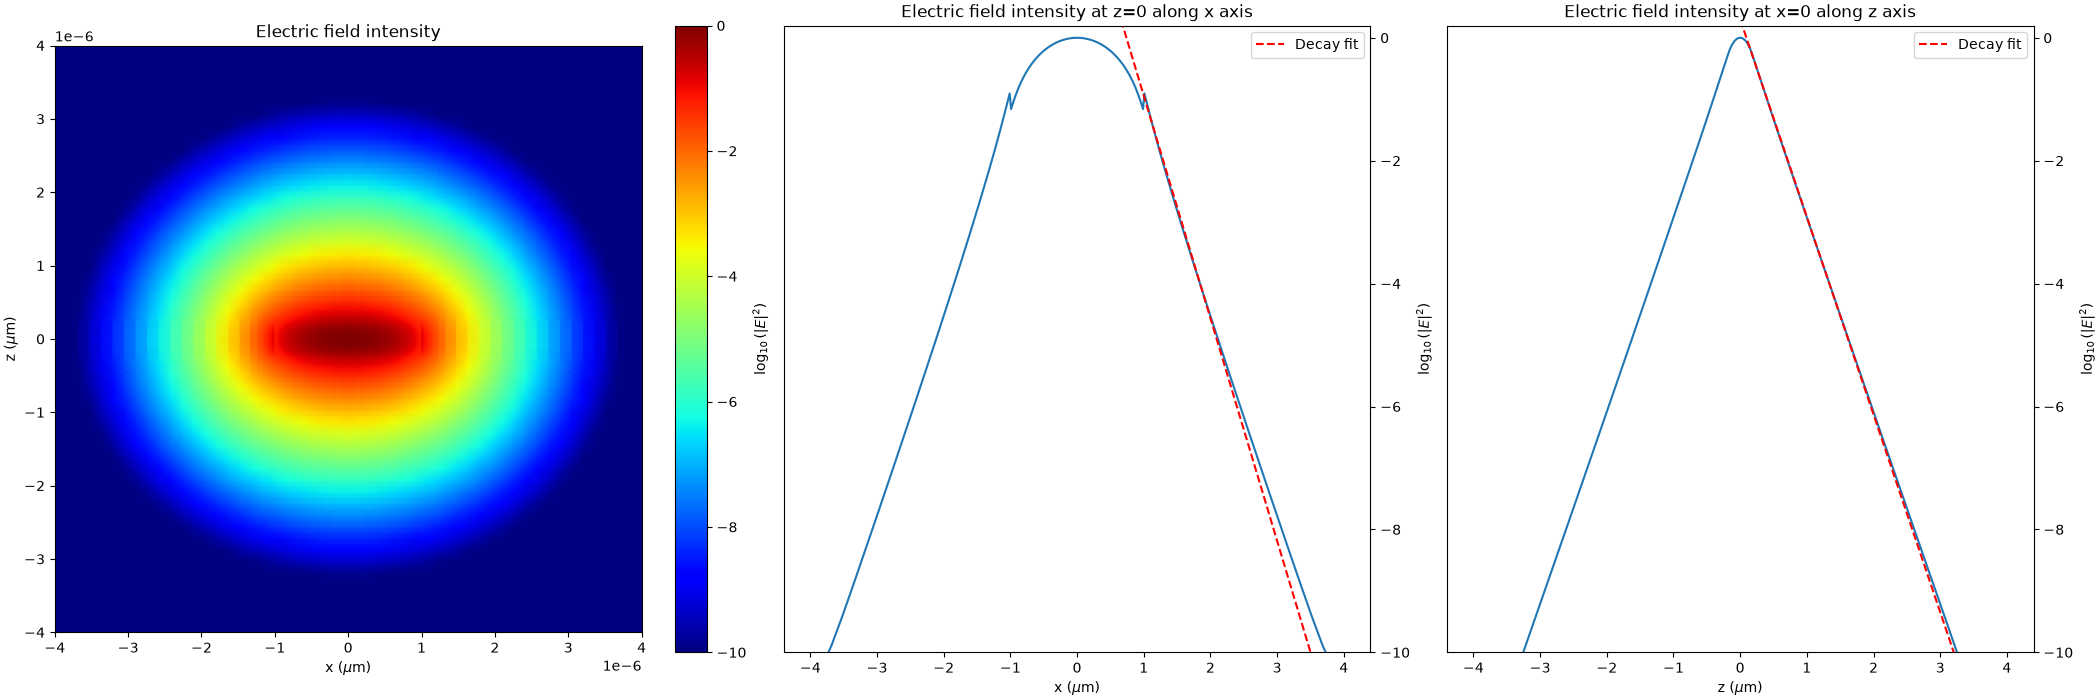

In [148]:
# Initial simulation

mode_solver.findmodes()

E = mode_solver.getresult("FDE::data::mode1", "E")
Ex, Ey, Ez = [np.squeeze(E["E"][..., i]) for i in range(3)]
x, z = np.squeeze(E["x"]), np.squeeze(E["z"])

decay = px.get_field_decay(Ex, Ey, Ez, margin=3)
confinement = px.get_field_confinement(Ex, Ey, Ez, x=x, z=z, radius=initial_core_width)

xmin = initial_core_width/2
xmax = (initial_fde_width/2)*0.75
slope_xp, intercept_xp = px.get_decay_slope(
    Ex, Ey, Ez, 
    x=x, 
    amin=xmin,
    amax=xmax,
)

zmin = core_thickness/2
zmax = (initial_fde_height/2)*0.75
slope_zp, intercept_zp = px.get_decay_slope(
    Ex, Ey, Ez, 
    z=z, 
    amin=zmin,
    amax=zmax,
)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(21, 7), constrained_layout=True)

# Efield
px.plot_field(
    Ex, Ey, Ez, 
    x=x, z=z,
    vmin=-10, vmax=0,
    ax=ax1
)
ax1.set_title('Electric field intensity')

# X decay
Eslice_x = px.get_field_intensisty_slice(
    Ex, Ey, Ez,
    x=x,
    scale="log"
)
ax2.plot(x*1e6, Eslice_x)
ax2.set_title('Electric field intensity at z=0 along x axis')
ax2.set_xlabel(r'x ($\mu$m)')
ax2.set_ylabel(r'$\log_{10}(|E|^2)$')
ax2.yaxis.tick_right()
ax2.yaxis.set_label_position("right")
ax2.set_ylim(-10, 0.2)

# X Decay fit
y = slope_xp * x + intercept_xp
ax2.plot(
    x*1e6, y,
    color='red', 
    linestyle='--', 
    linewidth=1.5, 
    label=f'Decay fit'
)
ax2.legend(loc='upper right')

# Z decay
Eslice_z = px.get_field_intensisty_slice(
    Ex, Ey, Ez,
    z=z,
    scale="log"
)
ax3.plot(z*1e6, Eslice_z)
ax3.set_title('Electric field intensity at x=0 along z axis')
ax3.set_xlabel(r'z ($\mu$m)')
ax3.set_ylabel(r'$\log_{10}(|E|^2)$')
ax3.yaxis.tick_right()
ax3.yaxis.set_label_position("right")
ax3.set_ylim(-10, 0.2)

# Z Decay fit
y = slope_zp * z + intercept_zp
ax3.plot(
    z*1e6, y,
    color='red', 
    linestyle='--', 
    linewidth=1.5, 
    label=f'Decay fit'
)
ax3.legend(loc='upper right')

plt.show()

## Width Sweep

This cell is incrementaly increasing width of the waveguide core and calculating modes for each waveguide variant.
Mode tracking is implementd using lumerical `mode.overlap()` method. 

In [149]:
def update_core_width(mode_solver, core_width):
    mode_solver.switchtolayout()
    mode_solver.select("core")
    mode_solver.set("x span", core_width)

def get_mode_data(mode_solver, mode_name):
    mode_data = {
        "f": mode_solver.getdata(mode_name, "f"),
        "neff": mode_solver.getdata(mode_name, "neff").item(),
        "ng": mode_solver.getdata(mode_name, "ng").item(),
        "loss": mode_solver.getdata(mode_name, "loss"),
        "TE polarization fraction": mode_solver.getdata(mode_name, "TE polarization fraction"),
        "waveguide TE-TM fraction": mode_solver.getdata(mode_name, "waveguide TE-TM fraction"),
        "mode effective area": mode_solver.getdata(mode_name, "mode effective area"),

        "x": mode_solver.getdata(mode_name, "x"),
        "y": mode_solver.getdata(mode_name, "y"),
        "z": mode_solver.getdata(mode_name, "z"),

        "Ex": mode_solver.getdata(mode_name, "Ex"),
        "Ey": mode_solver.getdata(mode_name, "Ex"),
        "Ez": mode_solver.getdata(mode_name, "Ex"),

        "Hx": mode_solver.getdata(mode_name, "Hx"),
        "Hy": mode_solver.getdata(mode_name, "Hy"),
        "Hz": mode_solver.getdata(mode_name, "Hz"),
    }
    
    return mode_data
    
def get_overlap_map(mode_solver):
    modes_count = int(mode_solver.nummodes())

    triplets = []
    for r in range(1, modes_count+1):
        mode_dcard = f"ref_mode{r}"
        for m in range(1, modes_count+1):
            mode_source = f"FDE::data::mode{m}"
            try:
                overlap_score = mode_solver.overlap(mode_source, mode_dcard)[0]
            except Exception:
                overlap_score = 0

            triplets.append((overlap_score, r, m))

    triplets.sort(key=lambda x: x[0], reverse=True)

    assigned_refs = set()
    asigned_modes = set()
    mapping = {}

    for ov, r, m in triplets:
        if r not in assigned_refs and m not in asigned_modes:
            assigned_refs.add(r)
            asigned_modes.add(m)
            mapping[r] = f"FDE::data::mode{m}"

    return mapping

sweep_data = []
for i, w in enumerate(reversed(width_sweep)):
    # Update core width
    update_core_width(mode_solver, w)

    # Find modes
    n_modes = int(mode_solver.findmodes())

    # Init D-CARDs with modes
    if i == 0:
        for m in range(1, n_modes + 1):
            mode_solver.copydcard(f"FDE::data::mode{m}", f"ref_mode{m}")

    # Data extraction + mode tracking
    mapping = get_overlap_map(mode_solver)

    modes = []
    for m in range(1, n_modes + 1):
        # Modes tracking on
        best_mode = mapping.get(m)

        # Modes tracking off
        #best_mode = f"FDE::data::mode{m}"
        mode_data = get_mode_data(mode_solver, best_mode)
        modes.append(mode_data)

    sweep_data.append({
        "width": w,
        "modes": modes,
    })

    # Update D-CARDs
    try:
        mode.cleardcard()
        for m in range(1, n_modes + 1):
            best_mode = mapping.get(m)
            if best_mode is not None:
                mode.copydcard(best_mode, f"ref_mode{m}")
    except Exception as e:
        pass

In [150]:
# Get refractive index of cladding used in simulation

frequency_center = C / wavelength_center
clad_nk_complex = mode_solver.getmodeindex(clad_material, frequency_center).item()
clad_n = np.real(clad_nk_complex)

print(f"Clad refractive index at wavelength: {wavelength_center * 1e9:.1f} nm is {clad_n:.4f}")

Clad refractive index at wavelength: 1550.0 nm is 1.4440


In [151]:
# Label guided modes

for step in sweep_data:
    for mode in step["modes"]:
        neff = np.real(mode["neff"])
        te_fraction = mode["TE polarization fraction"]
        
        label = None
        if neff >= clad_n:
            label = "quasi-TE" if te_fraction >= 0.5 else "quasi-TM"
            
        mode.update({"label": label})

In [152]:
# Export results

filename = f"results/{experiment_name}_" + datetime.now().strftime("%Y%m%d_%H%M%S") + ".npz"
np.savez(filename, sweep_data=sweep_data)
print(f"Data saved under {filename}")

Data saved under results/si3n4_h360nm_wsweep_20261113_003859.npz


In [158]:
# Load results
filename = "results/si3n4_h360nm_wsweep_20261113_003859.npz"

data = np.load(filename, allow_pickle=True)
sweep_data = data["sweep_data"].tolist()
print(f"Data loaded from {filename}")

Data loaded from results/si3n4_h360nm_wsweep_20261113_003859.npz


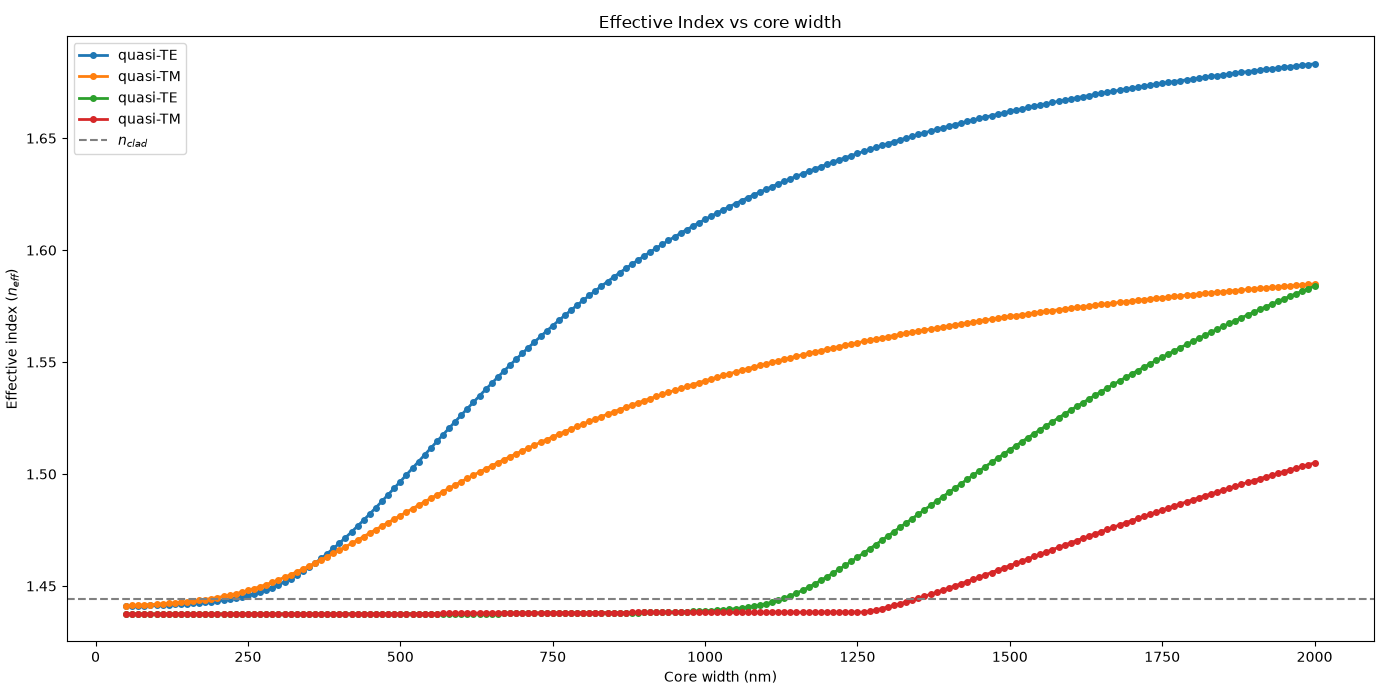

In [159]:
widths_nm = np.array([step["width"] * 1e9 for step in sweep_data])
max_modes = max(len(step["modes"]) for step in sweep_data)
neff_matrix = np.full((len(sweep_data), max_modes), np.nan)
label_matrix = np.full((len(sweep_data), max_modes), np.nan)

for i, step in enumerate(sweep_data):
    for m_idx, mode in enumerate(step["modes"]):
        neff_matrix[i, m_idx] = np.real(mode["neff"])
        label_matrix[i, m_idx] = (
            1 if mode["label"] == "quasi-TE" else
            0 if mode["label"] == "quasi-TM" else
            np.nan
        )

curves_labels = np.where(
    np.nanmean(label_matrix, axis=0) >= 0.5,
    "quasi-TE",
    "quasi-TM"
)

plt.figure(figsize=(14, 7))
plt.title("Effective Index vs core width")
plt.xlabel("Core width (nm)")
plt.ylabel("Effective index ($n_{eff}$)")
plt.tight_layout()
for m_idx in range(max_modes):
    plt.plot(
        widths_nm,
        neff_matrix[:, m_idx],
        marker="o",
        markersize=4,
        linestyle="-",
        linewidth=2,
        label=f"{curves_labels[m_idx]}"
    )
plt.axhline(y=clad_n, color='gray', linestyle='--', linewidth=1.5, label=f"$n_{{clad}}$")
plt.legend(fontsize=10, loc="best")
plt.show()